In [251]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

K-MEANS CLUSTERRING

In [252]:
X, y_true = make_blobs(n_samples=500, centers=3, cluster_std=0.60, random_state=42)

In [253]:
df = pd.DataFrame(X, columns=['Feature1', 'Feature2'])

In [254]:
df

,Feature1,Feature2
0,-6.190063,-7.302015
1,3.021747,1.940593
2,5.953761,1.488191
3,-2.744463,8.136177
4,5.360607,1.728324
...,...,...
495,-6.040014,-6.325329
496,-2.555459,9.218977
497,4.438408,2.974583
498,-7.193261,-6.250704


In [255]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

In [256]:
X_scaled

array([[-9.69818350e-01, -1.33993820e+00],
       [ 9.63343617e-01,  8.22475346e-02],
       [ 1.57864695e+00,  1.26351772e-02],
       [-2.46735247e-01,  1.03557927e+00],
       [ 1.45416962e+00,  4.95852224e-02],
       [ 1.40747082e+00,  8.22344111e-03],
       [-7.92177264e-01, -1.28388698e+00],
       [ 1.33697413e+00,  8.26220693e-02],
       [ 1.16849128e+00,  7.41152400e-02],
       [-1.19320161e+00, -1.27260956e+00],
       [ 1.22150712e+00, -1.25922376e-02],
       [-5.14797137e-02,  1.09492794e+00],
       [ 7.12157877e-02,  9.90472440e-01],
       [-1.25480095e-01,  1.27553591e+00],
       [ 1.33940654e+00,  2.78868839e-01],
       [ 1.43619041e+00, -7.51130357e-02],
       [-2.06430378e-01,  1.26334617e+00],
       [-1.25589470e+00, -1.23971291e+00],
       [-1.10416740e+00, -1.17664933e+00],
       [-3.36666506e-01,  1.06025816e+00],
       [ 1.12682035e+00,  1.39235617e-01],
       [-1.71064404e-01,  9.89772412e-01],
       [ 1.37551647e+00,  1.15995990e-01],
       [-9.

In [257]:
inertia = []
K_range = range(1,11)

In [258]:
for k in K_range:
  kmeans = KMeans(n_clusters = k, random_state = 42)
  kmeans.fit(X_scaled)
  inertia.append(kmeans.inertia_)

In [259]:
inertia

[1000.0,
 297.89541410517216,
 11.575484723104978,
 9.752067977356841,
 8.257175272446279,
 6.917577320416798,
 6.334755391595288,
 5.704177177901428,
 5.0602341335320755,
 4.762361898130395]

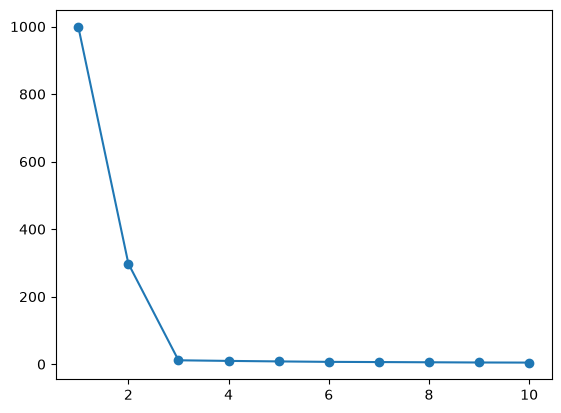

In [260]:
plt.plot(K_range, inertia, marker = 'o')

In [261]:
kmeans_final = KMeans(n_clusters=3, random_state=42)

In [262]:
cluster_labels = kmeans_final.fit_predict(X_scaled)

In [263]:
cluster_labels

array([1, 0, 0, 2, 0, 0, 1, 0, 0, 1, 0, 2, 2, 2, 0, 0, 2, 1, 1, 2, 0, 2,
       0, 1, 1, 0, 0, 1, 1, 2, 0, 2, 2, 2, 0, 0, 0, 0, 1, 1, 0, 2, 2, 2,
       2, 0, 0, 0, 0, 1, 1, 2, 1, 1, 0, 2, 2, 1, 0, 1, 1, 2, 0, 1, 0, 1,
       0, 1, 2, 0, 0, 0, 0, 1, 2, 1, 2, 0, 2, 2, 1, 2, 0, 2, 1, 1, 1, 1,
       0, 2, 1, 0, 2, 0, 0, 1, 2, 2, 2, 1, 0, 2, 2, 1, 1, 2, 2, 1, 2, 1,
       1, 1, 1, 1, 1, 0, 2, 1, 0, 1, 2, 2, 0, 0, 1, 0, 2, 0, 1, 1, 1, 0,
       0, 1, 0, 1, 1, 1, 0, 2, 1, 1, 0, 0, 1, 1, 1, 2, 2, 2, 0, 1, 0, 0,
       2, 1, 2, 1, 0, 0, 1, 1, 2, 2, 1, 2, 2, 0, 1, 1, 1, 2, 2, 1, 1, 2,
       2, 0, 0, 0, 2, 1, 2, 2, 1, 1, 2, 0, 2, 1, 1, 1, 1, 1, 2, 0, 2, 2,
       1, 0, 2, 2, 1, 1, 0, 1, 0, 2, 2, 1, 1, 0, 1, 2, 2, 1, 2, 1, 2, 0,
       0, 2, 1, 2, 0, 2, 2, 1, 0, 0, 0, 0, 2, 1, 1, 1, 2, 0, 2, 0, 0, 0,
       2, 2, 1, 1, 0, 2, 2, 0, 2, 2, 2, 2, 0, 2, 1, 2, 1, 2, 2, 2, 1, 2,
       0, 0, 0, 2, 0, 0, 2, 2, 0, 1, 2, 2, 2, 2, 1, 1, 2, 0, 2, 2, 1, 2,
       0, 1, 0, 0, 1, 2, 2, 2, 1, 2, 1, 0, 0, 2, 0,

In [264]:
df['cluster'] = cluster_labels

<Axes: xlabel='Feature1', ylabel='Feature2'>

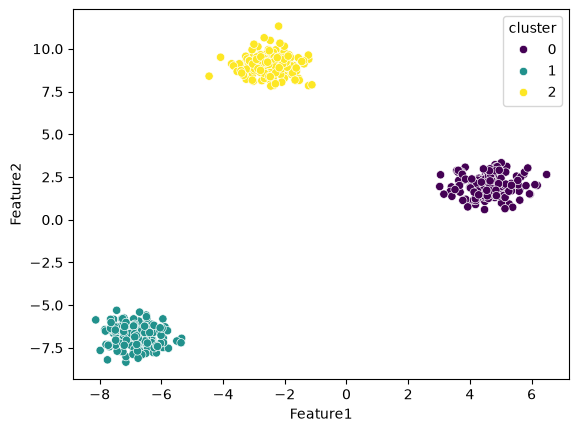

In [265]:
sns.scatterplot(x = df['Feature1'],
                y = df['Feature2'],
                hue=df['cluster'],
                palette='viridis')

DB SCAN CUSTERING

In [266]:
from sklearn.datasets import make_moons

In [267]:
from sklearn.cluster import KMeans, DBSCAN

In [268]:
X, y_true = make_moons(n_samples=500, noise=0.05, random_state=42)

In [269]:
df = pd.DataFrame(X, columns=['Feature1', 'Feature2'])

In [270]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

In [271]:
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

In [272]:
df['kmeans_cluster'] = kmeans_labels

<Axes: xlabel='Feature1', ylabel='Feature2'>

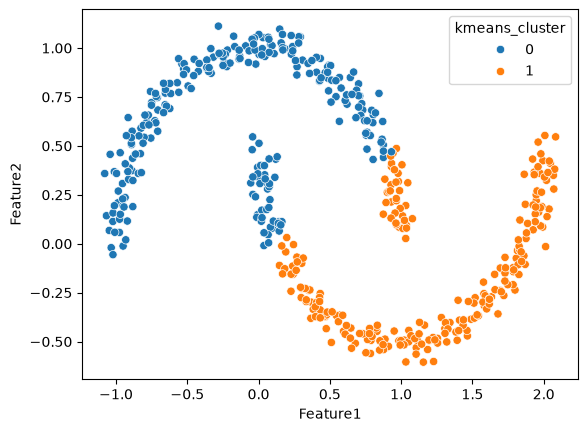

In [273]:
sns.scatterplot(x = df['Feature1'], y = df['Feature2'], hue=df['kmeans_cluster'], palette='tab10')

In [274]:
dbscan = DBSCAN(eps=0.3 , min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

In [275]:
df['dbscan_cluster'] = dbscan_labels

<Axes: xlabel='Feature1', ylabel='Feature2'>

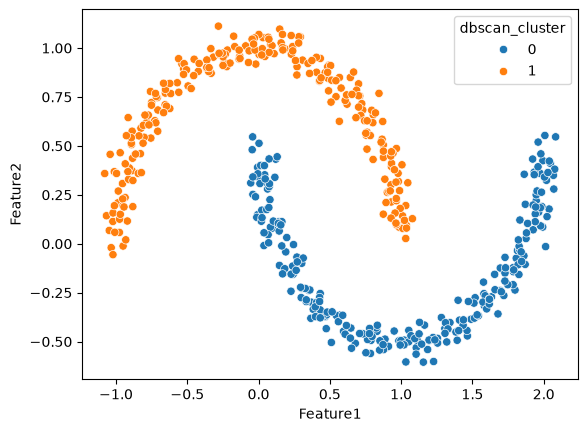

In [276]:
sns.scatterplot(x = df['Feature1'], y = df['Feature2'], hue=df['dbscan_cluster'], palette='tab10')